In [16]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def execute_and_plot(circuit, shots):
    # Import the AerSimulator from Qiskit Aer for simulating quantum circuits
    backend = AerSimulator(method="statevector")  # Use the statevector method for full quantum state simulation
    # Transpile the quantum circuit to optimize it for the chosen backend
    qc_compiled = transpile(circuit, backend)

    # Run the original (not transpiled) circuit on the simulator with 32 shots (repetitions)
    job_sim = backend.run(circuits=circuit, shots=shots)

    # Retrieve the result of the simulation job
    result = job_sim.result()

    # Extract the counts (measurement outcomes and their frequencies) from the result
    counts = result.get_counts(circuit)

    # Plot a histogram of the measurement results
    return plot_histogram(counts)


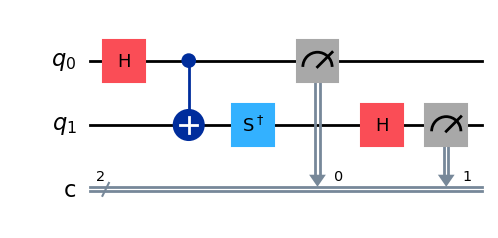

In [2]:
# Quantum Circuit Demonstrating the CHSH Game

from qiskit import QuantumCircuit
import numpy as np

# Create a quantum circuit with 2 qubits and 2 classical bits
# Qubit 0: Alice, Qubit 1: Bob
circuit = QuantumCircuit(2, 2)

# Step 1: Prepare a Bell state (entanglement)
circuit.h(0)
circuit.cx(0, 1)

# Step 2: Alice and Bob choose their measurement bases
# For demonstration, let's use x=0 (Alice) and y=0 (Bob)
# In the real CHSH game, x and y are random bits (0 or 1)

x = 0  # Alice's input bit
y = 0  # Bob's input bit

# Alice's measurement basis
if x == 0:
    # Measure in the Z basis (do nothing)
    pass
else:
    # Measure in the X basis (apply H)
    circuit.h(0)

# Bob's measurement basis
if y == 0:
    # Measure in (Z+X)/sqrt(2) basis (apply S† then H)
    circuit.sdg(1)
    circuit.h(1)
else:
    # Measure in (Z-X)/sqrt(2) basis (apply S then H)
    circuit.s(1)
    circuit.h(1)

# Step 3: Measure both qubits
circuit.measure(0, 0)  # Alice
circuit.measure(1, 1)  # Bob

# Draw the circuit
circuit.draw('mpl')

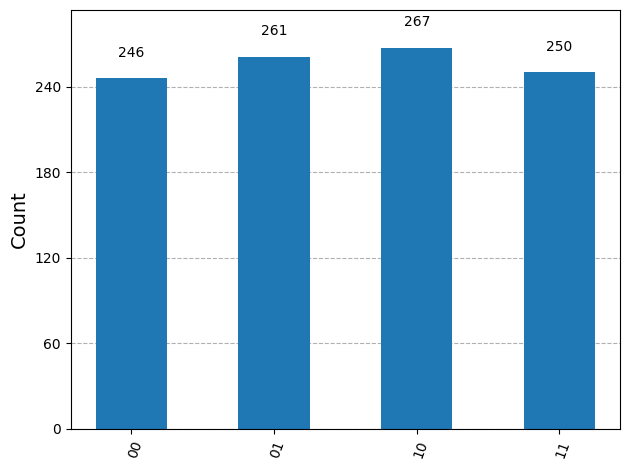

In [4]:
execute_and_plot(circuit=circuit, shots=1024)

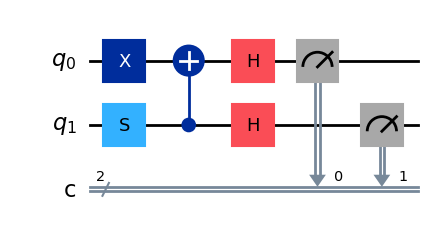

In [19]:
circuit = QuantumCircuit(2,2)

circuit.x(0)
circuit.s(1)
circuit.cx(1, 0)
circuit.h(1)
circuit.h(0)

circuit.measure(0, 0)
circuit.measure(1, 1)

circuit.draw('mpl')

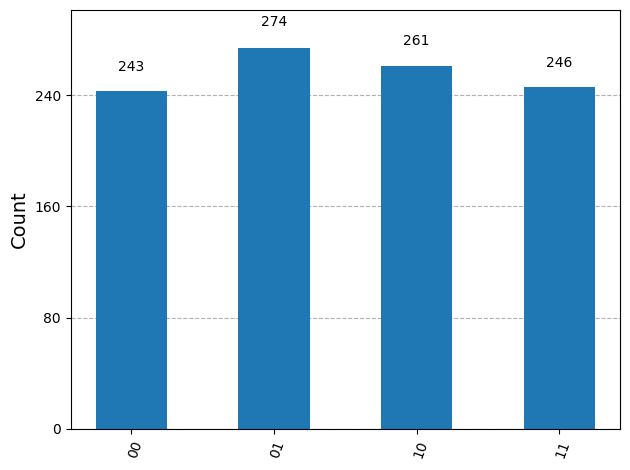

In [20]:
execute_and_plot(circuit=circuit, shots=1024)

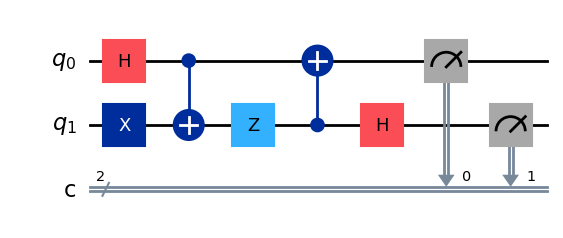

In [23]:
circuit = QuantumCircuit(2,2)

circuit.x(1)
circuit.h(0)
circuit.cx(0, 1)
circuit.z(1)
circuit.cx(1,0)
circuit.h(1)
circuit.measure(0, 0)
circuit.measure(1, 1)

circuit.draw('mpl')

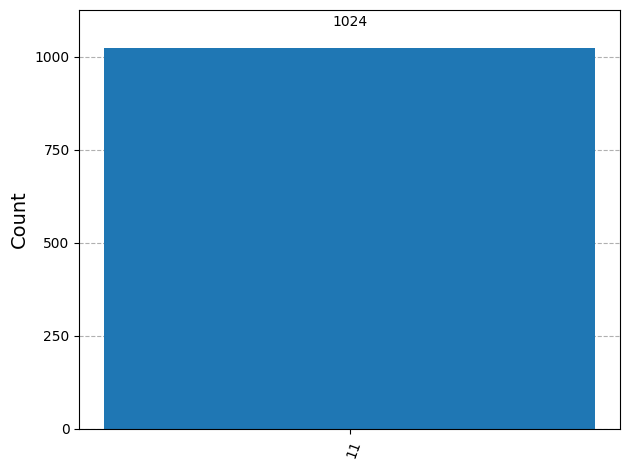

In [24]:
execute_and_plot(circuit=circuit, shots=1024)
